<a href="https://colab.research.google.com/github/pgomemon1605/analysis-connectatel/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# Mostrar las primeras filas de cada DataFrame
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


In [ ]:
# Verificar valores faltantes según el tipo de actividad
print(
    usage.groupby('type')[['duration', 'length']]
    .agg(lambda col: col.isna().mean() * 100)
)

       duration     length
type                      
call   0.000000  99.932991
text  99.927576   0.000000



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### Diagnóstico de valores nulos

**Dataset `users`**

- **`city` (11,73 % de nulos):** Se identifican 469 usuarios sin ciudad registrada. **Recomiendo investigar** el origen de los faltantes y conservar los usuarios, utilizando `"Unknown"` cuando sea necesario segmentar geográficamente.
- **`churn_date` (88,35 % de nulos):** Se identifican 3.534 usuarios sin fecha de abandono. **Recomiendo conservar** los valores nulos, previa validación de que correspondan a clientes que continúan activos.

**Dataset `usage`**

- **`date` (0,125 % de nulos):** Se identifican 50 registros sin fecha. **Recomiendo investigar** si es posible recuperar la información y, de lo contrario, excluir estos registros únicamente de los análisis que requieran fechas.
- **`duration` (55,19 % de nulos):** El análisis por tipo de actividad muestra que el 99,93 % de los mensajes (`text`) no tiene duración registrada, mientras que todas las llamadas (`call`) sí la tienen. **Recomiendo conservar** los nulos estructurales, ya que la duración corresponde a las llamadas.
- **`length` (44,74 % de nulos):** El 99,93 % de las llamadas (`call`) no presenta longitud, mientras que todos los mensajes (`text`) tienen este dato. **Recomiendo conservar** los nulos estructurales, ya que la longitud corresponde a los mensajes.

**Observación adicional:** Se identificaron 28 registros con valores presentes en campos que no corresponden a su tipo de actividad. Se revisarán posteriormente, durante la validación de datos inválidos y sentinels.

**Conclusión:** No todos los valores faltantes representan errores. El tratamiento debe depender del significado de cada variable y de su impacto en el análisis. Por ello, se prioriza conservar la información válida y evitar eliminaciones o imputaciones innecesarias.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- **La columna `user_id`:** Contiene 4.000 identificadores numéricos, con valores entre 10.000 y 13.999. El rango es coherente con la cantidad de registros, aunque se debe verificar posteriormente que no existan identificadores duplicados.

- **La columna `age`:** Presenta edades entre -999 y 79 años, con una media de 33,74 y una mediana de 47 años. El valor -999 es un posible centinela que representa información inválida y afecta el promedio y la desviación estándar (123,23). Se recomienda identificar estos registros y reemplazar el centinela por un valor nulo durante la etapa de limpieza.

In [ ]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- **Las columnas `id` y `user_id`:** La columna `id` contiene 40.000 registros con valores entre 1 y 40.000, mientras que `user_id` presenta valores entre 10.000 y 13.999, coherentes con el rango de identificadores del dataset `users`. Se recomienda conservar ambas columnas y verificar posteriormente la unicidad de `id` y la correspondencia de `user_id` con los usuarios registrados.

- **Las columnas `duration` y `length`:** La duración de las llamadas presenta una media de 5,20 y una mediana de 3,50, con valores entre 0 y 120. La longitud de los mensajes presenta una media de 52,13 y una mediana de 50, con valores entre 0 y 1490. Los máximos de 120 y 1490 son sospechosos porque se alejan considerablemente de los valores habituales y coinciden con los encontrados previamente en registros inconsistentes. Se recomienda investigar si corresponden a valores centinela y revisar los valores en cero antes de realizar la limpieza.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(columna)
    print(users[columna].value_counts(dropna=False))

city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
plan
Basico     2595
Premium    1405
Name: plan, dtype: int64


- **La columna `city`:** Presenta seis ciudades registradas, 469 valores nulos (11,73 %) y 96 registros con el valor `?` (2,40 %), que podría ser un centinela de información desconocida. Se recomienda convertir `?` en un valor nulo y evaluar posteriormente cómo tratar los 565 registros sin ciudad válida (14,13 %), evitando eliminar usuarios innecesariamente.

- **La columna `plan`:** Presenta dos categorías: `Basico` (2.595 usuarios, 64,88 %) y `Premium` (1.405 usuarios, 35,13 %). No se observan valores nulos ni categorías inesperadas. Se recomienda conservar los valores actuales sin modificaciones.

In [ ]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- **La columna `type`:** Presenta dos categorías: `text` (22.092 registros, 55,23 %) y `call` (17.908 registros, 44,77 %). No se identifican valores nulos, categorías inválidas ni posibles sentinels. Se recomienda conservar los valores actuales sin modificaciones, ya que permiten diferenciar el consumo de mensajes y llamadas.



---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

### Diagnóstico de valores inválidos o sentinels

**Dataset `users`**

- **`age`:** Se identificó el valor `-999`, que es inválido para una edad y constituye un posible centinela. **Acción:** reemplazarlo por un valor nulo (`NaN`) durante la limpieza y evaluar posteriormente su tratamiento.
- **`city`:** Se encontraron 96 registros con el valor `?` (2,40 %), además de 469 valores nulos. **Acción:** reemplazar `?` por `NaN` y evaluar cómo conservar los 565 usuarios sin ciudad identificada, evitando eliminaciones innecesarias.
- **`user_id` y `plan`:** No se identificaron valores inválidos evidentes en la exploración. **Acción:** conservar los datos sin modificaciones por ahora.

**Dataset `usage`**

- **`duration`:** Se identificaron valores entre 0 y 120, siendo 120 un máximo sospechoso por su distancia respecto a la mediana de 3,5. **Acción:** investigar si representa un centinela o un consumo válido antes de modificarlo.
- **`length`:** Se encontraron valores entre 0 y 1490, siendo 1490 un máximo sospechoso frente a la mediana de 50. **Acción:** verificar si corresponde a un valor extremo válido o un centinela antes de corregirlo.
- **`duration` y `length` según `type`:** Se identificaron 28 registros (0,07 %) con información en campos no esperados para su tipo de actividad. **Acción:** revisar estas inconsistencias durante la limpieza, procurando conservar las transacciones válidas.
- **`id`, `user_id` y `type`:** No se identificaron valores inválidos evidentes. **Acción:** conservarlos y verificar posteriormente la integridad de los identificadores.

**Conclusión:** Se identificaron valores claramente inválidos en `age` y `city`, además de valores sospechosos en `duration` y `length`. Se recomienda corregir los centinels confirmados y validar los valores extremos antes de eliminarlos o reemplazarlos, para evitar pérdida de información útil.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna 'reg_date' de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En reg_date: Se identificaron registros de usuarios correspondientes a 2022 (1.314), 2023 (1.316), 2024 (1.330) y 2026 (40). Estos últimos representan el 1 % de los usuarios y son inconsistentes con el periodo de análisis, que finaliza en 2024. Se recomienda revisar estas 40 fechas y tratarlas como inválidas si no es posible recuperar la fecha correcta.

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En date: Se identificaron 39.950 registros de actividad correspondientes a 2024, sin años fuera del periodo esperado. Sin embargo, existen 50 registros sin fecha válida (0,125 %). Se recomienda conservar las fechas válidas y revisar los registros faltantes antes de decidir su tratamiento.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Dataset `users` — Columna `reg_date`:** Se identificaron 40 registros con fechas de 2026 (1 % del total), posteriores al periodo de análisis que finaliza en 2024. Se consideran fechas inválidas para este estudio. **Acción recomendada:** revisar si es posible recuperar las fechas originales y, de lo contrario, reemplazarlas por `NaT` durante la limpieza, conservando los usuarios.

**Dataset `usage` — Columna `date`:** Los 39.950 registros con fecha válida corresponden a 2024, por lo que no se identificaron años fuera de rango. Sin embargo, existen 50 registros sin fecha (0,125 %). **Acción recomendada:** conservar las fechas válidas e investigar los registros faltantes antes de decidir si deben excluirse de los análisis temporales.

**Conclusión:** Se identificaron fechas fuera del periodo de estudio únicamente en `users`. Se recomienda corregir los valores inválidos sin eliminar registros completos innecesariamente, para preservar la información útil del análisis.

---


## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean() * 100)

type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean() * 100)

type
call    99.932991
text     0.000000
Name: length, dtype: float64

- **`duration`:** El 99,93 % de los mensajes (`text`) presenta valores nulos, mientras que las llamadas (`call`) tienen el 100 % de sus duraciones registradas. Esto indica que los faltantes dependen del tipo de actividad. **Recomendación:** conservar los nulos sin imputarlos, ya que la duración no aplica a los mensajes.

- **`length`:** El 99,93 % de las llamadas (`call`) presenta valores nulos, mientras que los mensajes (`text`) tienen el 100 % de sus longitudes registradas. **Recomendación:** conservar los nulos sin imputarlos, ya que la longitud no aplica a las llamadas.

**Conclusión:** Los valores faltantes dependen de la variable observada `type`, por lo que son compatibles con MAR. Sin embargo, se interpretan principalmente como **nulos estructurales**, asociados al tipo de servicio. No se recomienda eliminar registros ni imputar estos valores, pues se generaría información artificial. Los 28 registros con campos inesperados se revisarán en la etapa correspondiente.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", lambda x: x[usage.loc[x.index, "type"] == "call"].sum())
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg.columns = ['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,22.836934
std,17.689919,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,48.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

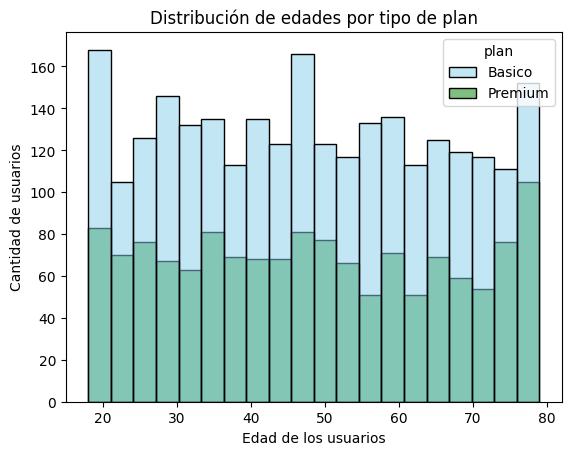

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=20)

plt.title('Distribución de edades por tipo de plan')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡 **Insights:**

- **Distribución:** Las edades presentan una distribución aproximadamente uniforme entre los 18 y 79 años, con algunas variaciones entre intervalos, pero sin un sesgo evidente hacia la derecha o la izquierda.
- **Plan Básico (azul):** Registra mayores frecuencias absolutas en prácticamente todos los rangos de edad, lo que es coherente con su mayor participación en la base de clientes (64,88 %).
- **Plan Premium (verde):** Tiene presencia en todos los rangos de edad y muestra un comportamiento visual relativamente similar al del plan Básico, aunque con menores frecuencias absolutas.
- **Conclusión:** No se observa una concentración de edades claramente diferenciada entre los dos planes. Sin embargo, las frecuencias absolutas no permiten establecer preferencias por edad, debido a las diferencias en el tamaño de ambos grupos.

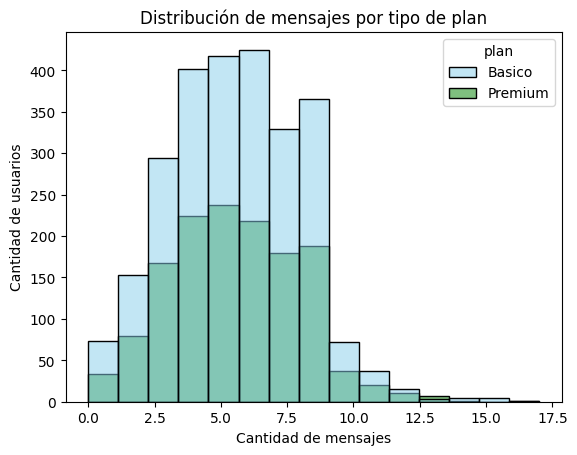

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=15)

plt.title('Distribución de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡 **Insights:**

- **Distribución:** La cantidad de mensajes presenta una distribución unimodal, con un ligero sesgo hacia la derecha. La mayor concentración de usuarios se encuentra entre 3 y 8 mensajes, mientras que pocos superan los 10.
- **Plan Básico (azul):** Presenta las frecuencias absolutas más altas, especialmente entre 4 y 7 mensajes. Esto es coherente con su mayor cantidad de usuarios.
- **Plan Premium (verde):** También concentra su actividad principalmente entre 3 y 8 mensajes, mostrando un patrón visual similar al del plan Básico.
- **Conclusión:** No se observan diferencias marcadas en la forma de la distribución de mensajes entre ambos planes. Sin embargo, para determinar si un plan presenta mayor consumo promedio sería necesario comparar sus estadísticas por separado.

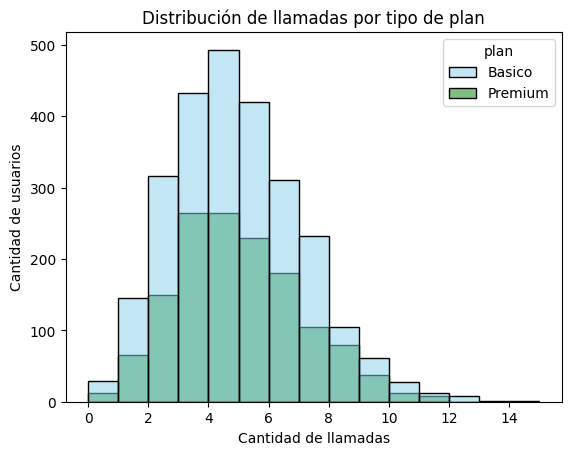

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=15)

plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

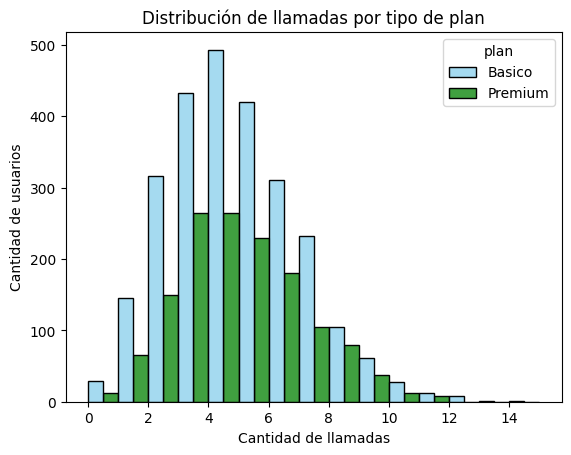

In [ ]:
# Histograma de llamadas con barras separadas
sns.histplot(data=user_profile, x='cant_llamadas',
             hue='plan', palette=['skyblue', 'green'],
             bins=15, multiple='dodge')

plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡 **Insights:**

- **Distribución:** La cantidad de llamadas presenta una distribución unimodal, con un ligero sesgo hacia la derecha. La mayor concentración se encuentra entre 3 y 6 llamadas por usuario, mientras que pocos superan las 10 llamadas.
- **Plan Básico (azul):** Presenta mayores frecuencias absolutas, especialmente entre 3 y 6 llamadas, con un pico alrededor de las 4 llamadas.
- **Plan Premium (verde):** Muestra un comportamiento similar, concentrado principalmente entre 3 y 6 llamadas, aunque con menores frecuencias absolutas.
- **Conclusión:** Ambos planes presentan patrones de llamadas visualmente similares. Las mayores frecuencias del plan Básico se relacionan con su mayor cantidad total de usuarios (64,88 %) y no demuestran por sí solas un mayor consumo individual.

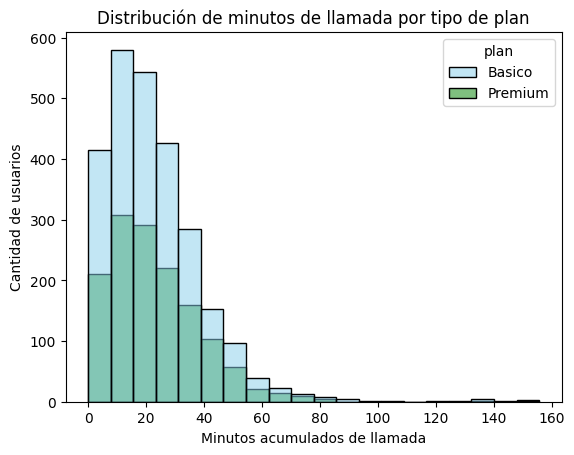

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=20)

plt.title('Distribución de minutos de llamada por tipo de plan')
plt.xlabel('Minutos acumulados de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡 **Insights:**

- **Distribución:** Los minutos acumulados de llamada presentan una distribución unimodal, fuertemente sesgada hacia la derecha. La mayor concentración de usuarios se encuentra aproximadamente entre 5 y 30 minutos, mientras que pocos superan los 60 minutos.
- **Plan Básico (azul):** Presenta mayores frecuencias absolutas, especialmente entre 10 y 30 minutos, con un pico cercano a los 15 minutos.
- **Plan Premium (verde):** Muestra una distribución similar, concentrada principalmente entre 5 y 30 minutos, aunque con menores frecuencias absolutas.
- **Valores extremos:** Se observa una cola prolongada hacia la derecha, con algunos usuarios que acumulan más de 100 minutos y un máximo general de 155,69 minutos. Estos valores podrían representar consumos atípicos que deberán evaluarse posteriormente.
- **Conclusión:** Ambos planes presentan patrones visualmente similares en los minutos de llamada. Las mayores frecuencias del plan Básico no demuestran un consumo individual superior, dado que este plan concentra el 64,88 % de los clientes.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

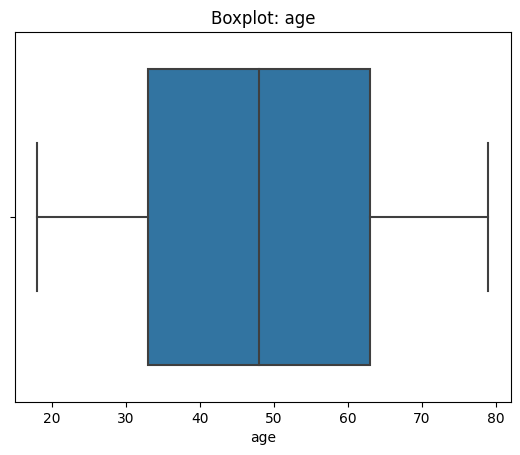

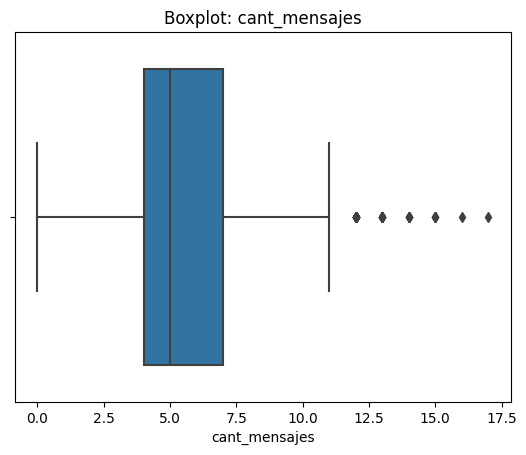

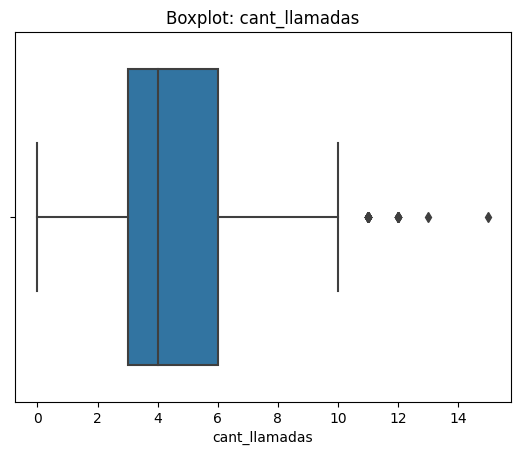

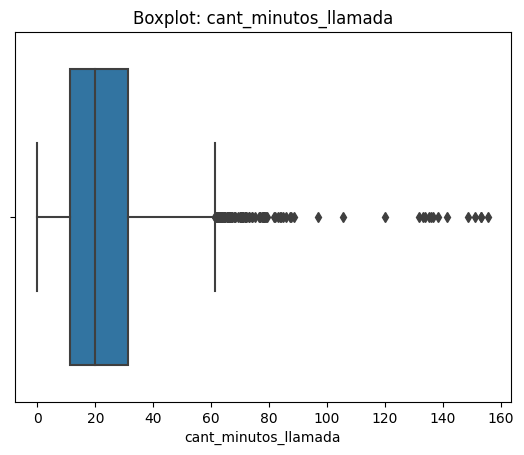

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡 **Insights:**

- **Age:** No presenta outliers. Las edades se encuentran entre 18 y 79 años, con una mediana de 48. Los valores están dentro de los límites esperados según el método IQR.

- **cant_mensajes:** Presenta outliers superiores, a partir de 12 mensajes aproximadamente, alcanzando un máximo de 17. Se observa que algunos usuarios envían considerablemente más mensajes que la mayoría.

- **cant_llamadas:** Presenta outliers superiores, a partir de 11 llamadas, con un máximo de 15. La mayoría de los usuarios registra entre 3 y 6 llamadas, mientras que un grupo reducido presenta una frecuencia mayor.

- **cant_minutos_llamada:** Presenta numerosos outliers superiores, aproximadamente desde los 61 minutos, con un máximo de 155,69. Es la variable con los valores extremos más pronunciados, lo que evidencia una mayor dispersión en el tiempo acumulado de llamadas.

**Conclusión:** Se identificaron valores atípicos en las tres variables de consumo, principalmente hacia la derecha de sus distribuciones. No necesariamente representan errores, ya que podrían corresponder a usuarios con mayor actividad. Se recomienda calcular los límites mediante el método IQR antes de decidir si requieren tratamiento.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡 Insights y decisión sobre outliers:

cant_mensajes: El límite superior IQR es 11,5 mensajes, mientras que el máximo es 17. Se identifican usuarios con una actividad de mensajería superior a la habitual. Recomiendo conservarlos, ya que pueden representar consumos reales.

cant_llamadas: El límite superior es 10,5 llamadas y el máximo registrado es 15. Los valores atípicos podrían corresponder a usuarios que realizan llamadas con mayor frecuencia. Recomiendo conservarlos, al no existir evidencia suficiente de errores.

cant_minutos_llamada: El límite superior es 61,32 minutos y el máximo alcanza 155,69. Presenta los valores extremos más pronunciados. Recomiendo conservarlos, pero considerar su influencia sobre los promedios y la dispersión.

Conclusión: Aunque las tres variables presentan outliers superiores, estos no necesariamente representan errores. Se recomienda mantenerlos para preservar los patrones reales de consumo y evitar perder información sobre usuarios de alta actividad.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

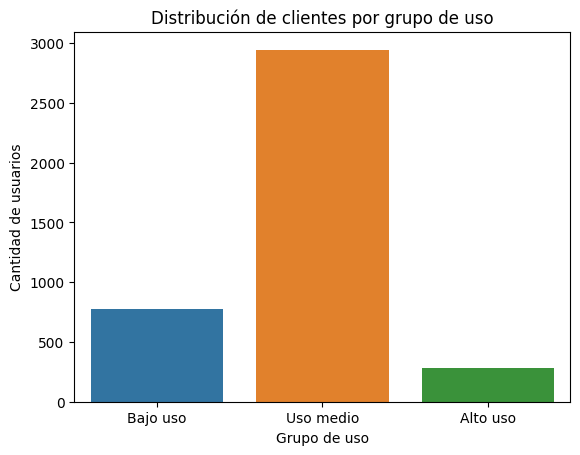

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])

plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

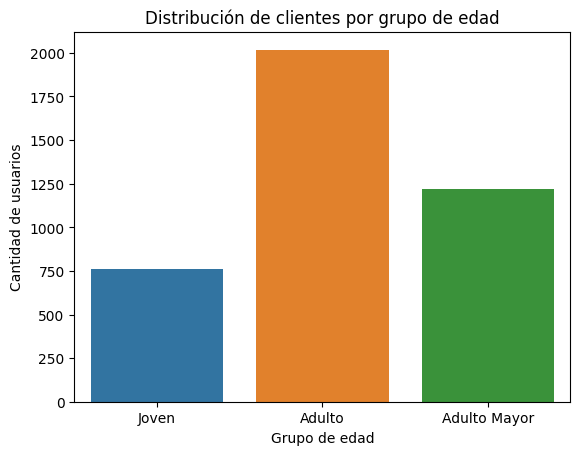

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

La segmentación por uso evidencia que **la mayoría de los clientes de ConnectaTel pertenece al grupo de Uso medio (aproximadamente 73 %)**, seguido de Bajo uso (20 %) y Alto uso (7 %). Esto sugiere oportunidades para desarrollar estrategias de activación dirigidas a usuarios de baja actividad y propuestas diferenciadas para aquellos con mayor consumo.

Por su parte, la segmentación por edad permite clasificar a los clientes en **Jóvenes, Adultos y Adultos Mayores**, facilitando la identificación de posibles diferencias en sus hábitos de consumo.

**En conjunto, ambas segmentaciones proporcionan una base para comprender mejor el comportamiento de los clientes y diseñar estrategias comerciales, de retención y personalización de servicios**, considerando tanto su nivel de actividad como su etapa de vida.


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

# Paso 7. Análisis ejecutivo para stakeholders — ConnectaTel

## 1. Calidad de los datos: problemas identificados y acciones recomendadas

El análisis de los 4.000 usuarios y 40.000 registros de actividad permitió identificar inconsistencias que podían afectar la calidad de los resultados.

| Variable | Hallazgo | Recomendación |
|---|---|---|
| `age` | Se detectó el valor inválido `-999`, que distorsionaba la media original de 33,74 años. | Se reemplazó por la mediana de las edades válidas, obteniendo una media corregida de 48,14 años. Implementar controles de edad en los formularios de registro. |
| `city` | 469 nulos (11,73 %) y 96 valores `?` (2,40 %). En total, 565 usuarios sin ciudad identificada (14,13 %). | Se estandarizó `?` como nulo. Se recomienda mejorar la captura de ubicación y utilizar una categoría de ciudad desconocida cuando sea necesario para evitar excluir clientes. |
| `reg_date` | 40 fechas de 2026 (1 %), fuera del periodo analizado. | Se reemplazaron por fechas nulas. Implementar validaciones que impidan registrar fechas fuera del rango permitido. |
| `usage.date` | 50 registros sin fecha (0,125 %). | Investigar si se puede recuperar la fecha y excluir estos eventos únicamente de análisis temporales que requieran ese dato. |
| `duration` y `length` | 55,19 % y 44,74 % de nulos, respectivamente. La mayoría son ausencias estructurales asociadas al tipo de actividad. | Conservar los nulos estructurales y establecer reglas de captura diferenciadas para llamadas y mensajes. |
| `churn_date` | 3.534 usuarios (88,35 %) sin fecha de abandono. | Validar si representan clientes activos antes de utilizar esta variable para indicadores de retención. |

Adicionalmente, se identificaron **28 eventos (0,07 %) con información en campos no esperados para su tipo de actividad**. Se recomienda revisar estos casos y reforzar las validaciones de los registros de consumo, sin eliminar automáticamente las transacciones.

**Implicación para el negocio:** Una mejor calidad de datos permite segmentar con mayor precisión, medir el consumo de forma confiable y tomar mejores decisiones comerciales.

---

## 2. Segmentación de clientes: comportamiento y oportunidades comerciales

### Segmentación por nivel de uso

La segmentación permitió identificar tres grupos de clientes según la cantidad de llamadas y mensajes registrados.

| Segmento | Participación aproximada | Hallazgo | Recomendación comercial |
|---|---:|---|---|
| **Uso medio** | 73 % | Es el grupo predominante de clientes. | Diseñar estrategias de fidelización y evaluar beneficios que incentiven un mayor aprovechamiento de los servicios. |
| **Bajo uso** | 20 % | Son usuarios con menos de 5 llamadas y menos de 5 mensajes. | Investigar las causas de la baja actividad y probar campañas de activación, acompañamiento o beneficios ajustados a su consumo. |
| **Alto uso** | 7 % | Son clientes con al menos 10 llamadas o 10 mensajes. | Evaluar paquetes adicionales y planes más flexibles, considerando sus necesidades específicas de consumo. |

*Los porcentajes son aproximaciones obtenidas de la visualización y deben confirmarse antes de utilizarlos como indicadores definitivos.*

### Segmentación por edad

Los clientes tienen entre 18 y 79 años, con una edad promedio de 48,14 años. Se crearon tres grupos:

- **Jóvenes (menores de 30 años):** explorar sus hábitos de comunicación y evaluar propuestas digitales o autogestionadas, si sus necesidades lo justifican.
- **Adultos (30 a 59 años):** identificar qué servicios utilizan con mayor frecuencia y evaluar beneficios ajustados a sus patrones reales de consumo.
- **Adultos Mayores (60 años o más):** investigar posibles necesidades de acompañamiento, accesibilidad y claridad de la información para facilitar el uso de los servicios.

**Implicación:** La edad puede servir como variable complementaria para diseñar experiencias diferenciadas, pero no debe utilizarse como único criterio comercial.

Los histogramas de edad por plan no mostraron diferencias visuales marcadas. Tampoco se ha comprobado una relación específica entre los grupos de edad y los niveles de consumo.

**Recomendación:** Cruzar posteriormente `grupo_edad`, `grupo_uso` y `plan` para identificar patrones concretos antes de diseñar ofertas específicas para cada generación.

---

## 3. ¿Qué segmentos representan mayor valor potencial?

El análisis permite identificar oportunidades, aunque todavía no es posible establecer qué segmento genera mayor rentabilidad económica.

**Uso medio — Prioridad por tamaño del segmento**

Es el segmento con mayor participación en la base de clientes.

- **Oportunidad:** fortalecer la permanencia y el aprovechamiento de los servicios entre una población numerosa.
- **Recomendación:** evaluar incentivos de fidelización y mejoras de los planes actuales, midiendo cambios en actividad y retención.

**Alto uso — Potencial de especialización comercial**

Estos clientes presentan una mayor frecuencia de llamadas o mensajes según los criterios establecidos.

- **Oportunidad:** identificar necesidades que podrían no estar suficientemente cubiertas por los planes actuales.
- **Recomendación:** evaluar beneficios adicionales, paquetes de consumo o planes flexibles, verificando primero si realmente necesitan más capacidad.

**Bajo uso — Oportunidad de activación**

Los clientes de este segmento presentan una actividad reducida.

- **Oportunidad:** comprender si su bajo consumo responde a preferencias, necesidades limitadas, barreras de uso o una posible desconexión con el servicio.
- **Recomendación:** investigar las causas antes de implementar campañas de activación y evaluar su efectividad.

**Conclusión comercial:** El Uso medio representa una oportunidad por su tamaño, el Alto uso por sus posibles necesidades especializadas y el Bajo uso por su potencial de activación. Sin embargo, mayor consumo no significa necesariamente mayor rentabilidad ni menor riesgo de abandono.

---

## 4. Patrones de consumo extremo: outliers e implicaciones

El análisis mediante boxplots y el método IQR permitió identificar valores atípicos superiores en las tres variables de consumo.

| Variable | Límite IQR superior | Máximo observado |
|---|---:|---:|
| Cantidad de mensajes | 11,50 | 17 |
| Cantidad de llamadas | 10,50 | 15 |
| Minutos acumulados de llamada | 61,32 | 155,69 |

Los minutos de llamada presentan la distribución más sesgada hacia la derecha, con usuarios que registran consumos considerablemente superiores a los habituales.

**Decisión analítica:** Se recomienda conservar los outliers, ya que no existe evidencia suficiente para considerarlos errores.

**Implicaciones y recomendaciones:**

- **Mensajes elevados:** investigar si estos usuarios requieren paquetes de mensajería más amplios o beneficios especializados.
- **Frecuencia elevada de llamadas:** evaluar si existen oportunidades para mejorar la oferta dirigida a clientes que llaman con mayor frecuencia.
- **Minutos acumulados elevados:** analizar si los clientes de mayor duración de llamadas tienen necesidades diferentes a quienes realizan muchas llamadas cortas.

**Recomendación transversal:** Comparar el consumo real con los beneficios incluidos en cada plan antes de proponer ampliaciones o migraciones.

Esto permitiría diferenciar clientes con alto consumo que ya están bien atendidos de aquellos para quienes podría resultar útil una oferta alternativa.

---

## 5. Recomendaciones para optimizar la oferta de planes

Actualmente, el **64,88 % de los clientes pertenece al plan Básico** y el **35,13 % al Premium**.

Aunque los gráficos muestran patrones de consumo visualmente similares entre ambos planes, todavía no permiten demostrar diferencias significativas de consumo individual ni determinar si existe una asignación óptima de los clientes a sus planes.

A partir de los hallazgos, se proponen cinco líneas de acción:

### 1. Evaluar la adecuación de los planes actuales

Comparar las necesidades reales de cada segmento con los minutos, mensajes y demás beneficios incluidos en Básico y Premium.

**Acción:** identificar posibles desajustes entre el consumo de los clientes y las características de sus planes.

### 2. Explorar ofertas flexibles para usuarios de Alto uso

Evaluar paquetes adicionales de llamadas o mensajes que permitan responder a necesidades de consumo superiores.

**Acción:** validar primero la demanda potencial y la conveniencia económica de estas ofertas.

### 3. Fortalecer la activación de usuarios de Bajo uso

Diseñar pruebas de comunicación y acompañamiento para comprender qué factores limitan la utilización de los servicios.

**Acción:** medir si estas intervenciones aumentan el uso y mejoran la vinculación de los clientes.

### 4. Desarrollar estrategias de fidelización para Uso medio

Aprovechar el tamaño de este segmento para evaluar beneficios que fortalezcan la relación con ConnectaTel.

**Acción:** probar incentivos segmentados y medir su efecto sobre el consumo y la permanencia.

### 5. Incorporar información de abandono e ingresos

Relacionar los segmentos con el comportamiento de churn y con indicadores económicos para priorizar las oportunidades de mayor impacto.

**Acción:** evaluar tasas de abandono, ingresos por cliente, costos y rentabilidad antes de tomar decisiones definitivas sobre precios o nuevos planes.

---

## 6. Conclusión ejecutiva

El análisis de ConnectaTel permitió transformar los registros de actividad en información útil para comprender el comportamiento de los clientes, detectar inconsistencias y construir segmentos comerciales.

Se identificó que **la mayoría de los usuarios presenta un nivel de consumo medio**, mientras que los grupos de baja y alta actividad ofrecen oportunidades diferenciadas de activación, fidelización y especialización de la oferta.

Asimismo, los valores extremos de consumo evidencian que algunos usuarios presentan necesidades distintas a las habituales, lo que justifica evaluar la flexibilidad y adecuación de los planes existentes.

**La recomendación principal es avanzar hacia una estrategia comercial basada en el comportamiento real de consumo**, combinando tres prioridades:

1. **Mejorar la calidad de los datos** para fortalecer la confiabilidad de las decisiones.
2. **Personalizar las acciones comerciales** según los segmentos de uso y sus necesidades verificadas.
3. **Evaluar la pertinencia de los planes actuales** antes de desarrollar nuevas ofertas, incorporando indicadores de retención y rentabilidad.

De esta manera, ConnectaTel podrá utilizar la analítica de datos para identificar oportunidades de mejora en la experiencia del cliente, fortalecer su vinculación y orientar decisiones comerciales con mayor evidencia.

### Análisis ejecutivo

#### ⚠️ Problemas detectados en los datos

- **Edades inválidas:** Se identificó el valor centinela `-999`, que distorsionaba la edad promedio (33,74 años). Tras reemplazarlo por la mediana de las edades válidas, la media se corrigió a 48,14 años.
- **Información geográfica incompleta:** Se encontraron 469 valores nulos (11,73 %) y 96 registros con `?` (2,40 %) en `city`. Después de la limpieza, 565 usuarios (14,13 %) quedaron sin ciudad identificada, lo que limita la segmentación geográfica.
- **Fechas inconsistentes:** Se detectaron 40 registros (1 %) con fechas de inscripción de 2026, fuera del periodo analizado. Se reemplazaron por valores nulos. Además, 50 eventos de uso (0,125 %) carecen de fecha.
- **Inconsistencias en el consumo:** Los valores nulos de `duration` y `length` son principalmente estructurales, pues dependen del tipo de actividad. Sin embargo, se identificaron 28 registros (0,07 %) con información en campos inesperados.

#### 🔍 Segmentos por Edad

- **Jóvenes (18–29 años):** Segmento definido para analizar sus hábitos de consumo e identificar posibles necesidades de comunicación digital y autogestión.
- **Adultos (30–59 años):** Segmento que permite explorar necesidades de comunicación y oportunidades de personalización según el consumo real.
- **Adultos Mayores (60 años o más):** Segmento relevante para investigar necesidades de accesibilidad, acompañamiento y claridad en la oferta de servicios.
- **Hallazgo general:** La edad promedio es de 48,14 años. Los histogramas por plan muestran distribuciones relativamente similares, sin diferencias visuales marcadas. Aún no se ha demostrado una relación específica entre edad y nivel de consumo.

#### 📊 Segmentos por Nivel de Uso

- **Uso medio (aproximadamente 73 %):** Es el segmento predominante. Representa una oportunidad para fortalecer la fidelización y evaluar beneficios que incentiven el aprovechamiento de los servicios.
- **Bajo uso (aproximadamente 20 %):** Registra menos de 5 llamadas y menos de 5 mensajes. Es un grupo relevante para investigar posibles barreras de uso y desarrollar estrategias de activación.
- **Alto uso (aproximadamente 7 %):** Incluye clientes con al menos 10 llamadas o 10 mensajes. Podrían requerir beneficios adicionales o planes más flexibles.
- **Consumos extremos:** Se detectaron valores atípicos superiores de hasta 17 mensajes, 15 llamadas y 155,69 minutos acumulados. Estos consumos podrían ser legítimos y revelar necesidades comerciales diferenciadas.
- **Distribución por plan:** El 64,88 % de los clientes pertenece al plan Básico y el 35,13 % al Premium. Los histogramas muestran patrones de consumo visualmente similares, sin evidencia suficiente para afirmar que un plan genera mayor consumo individual.

*Los porcentajes de los grupos de uso son aproximaciones visuales y deben verificarse antes de presentarlos como indicadores definitivos.*

#### ➡️ Esto sugiere que...

ConnectaTel tiene oportunidades para mejorar su oferta comercial mediante una segmentación basada en el comportamiento real de los clientes. La concentración de usuarios en Uso medio permite priorizar acciones de fidelización, mientras que los segmentos de Bajo y Alto uso presentan oportunidades de activación y personalización.

Los valores extremos de consumo también sugieren que algunos clientes podrían tener necesidades distintas a las cubiertas por sus planes actuales. Sin embargo, es necesario contrastar el consumo con los beneficios contratados antes de recomendar cambios.

**No es posible determinar todavía qué segmento es más rentable o presenta mayor riesgo de abandono**, ya que se requieren análisis adicionales de ingresos, costos y churn.

#### 💡 Recomendaciones

- **1. Optimizar la oferta para usuarios de Uso medio:** Evaluar beneficios de fidelización y promociones segmentadas. Medir su impacto sobre la utilización del servicio y la permanencia de los clientes.
- **2. Activar a los usuarios de Bajo uso:** Investigar las causas de su menor actividad y probar campañas de acompañamiento, comunicación y beneficios de activación.
- **3. Explorar planes flexibles para usuarios de Alto uso:** Comparar el consumo real con los minutos y mensajes incluidos en los planes actuales. Si se identifican necesidades no cubiertas, evaluar paquetes adicionales o nuevas modalidades.
- **4. Personalizar estrategias según edad y consumo:** Cruzar `grupo_edad`, `grupo_uso` y `plan` para identificar patrones verificables. Utilizar esos resultados para adaptar la comunicación, los canales de atención y los beneficios.
- **5. Fortalecer el plan Básico:** Dado que concentra cerca del 65 % de los clientes, evaluar oportunidades de fidelización y migración voluntaria a Premium únicamente cuando sus beneficios respondan a necesidades reales.
- **6. Mejorar la calidad de los datos:** Implementar validaciones automáticas de edad, ciudad y fechas, así como controles diferenciados para los registros de llamadas y mensajes.
- **7. Incorporar indicadores de retención y rentabilidad:** Analizar el abandono, los ingresos y los costos por segmento para priorizar las acciones comerciales con mayor impacto potencial.

**Conclusión ejecutiva:** ConnectaTel puede aprovechar la segmentación de clientes para evolucionar de una oferta general hacia estrategias más personalizadas. La prioridad es fortalecer la fidelización del segmento mayoritario, comprender las necesidades de los clientes de baja y alta actividad y evaluar ajustes en los planes con base en evidencia de consumo. Esto permitiría orientar mejor las decisiones comerciales, mejorar la experiencia del cliente y explorar oportunidades de crecimiento sostenible.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`